# 01 — Exploratory data analysis (SerbMR-2C)

This notebook shows the same analysis as `reports/eda/eda_report.md` (generated by `make eda`).
Both use the functions in `sentiment.eda`, so the numbers are identical.

Word-level statistics use the **training split only**, so nothing from validation/test data
influences modelling decisions. The validation split is used only to measure out-of-vocabulary rates.

In [1]:
%matplotlib inline
import pandas as pd
from IPython.display import Markdown, display

from sentiment.eda import plots
from sentiment.eda.report import insights, run_eda

pd.set_option("display.precision", 3)
splits = {
    name: pd.read_parquet(f"data/processed/{name}.parquet") for name in ("train", "val", "test")
}
train = splits["train"]
result = run_eda(splits)
train.head(3)

,id,text,label,source
0,394,All we need is love. A ne hipike. Project Nim ...,positive,SerbMR-2C
1,111,"Braćo i sestre, ovo bi lako mogao biti najveći...",positive,SerbMR-2C
2,136,Najbolja stvar u vezi There Will Be Blood Paul...,positive,SerbMR-2C


## Key insights
Generated from the statistics below, not written by hand.

In [2]:
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(insights(result), 1))))

1. **Classes are balanced** (negative 50.0%, positive 50.0% of 1682 reviews), and the stratified split preserves this in every split. Accuracy and macro F1 will therefore tell the same story, and no class re-weighting is needed.
2. **Review length carries no sentiment signal.** Median length is 437 (negative) vs. 442 (positive) words; a Mann-Whitney U test finds no significant difference (p = 0.34). Models cannot shortcut through length and must rely on content.
3. **Reviews are long, so transformer truncation matters.** The median review has ~439 words, and 89.7% exceed 256 words (33.0% exceed 512). Subword tokenization only increases the token count, so a 256-token model sees just the opening part of nearly every review. Head+tail truncation or chunking should be evaluated for BERTić.
4. **Rich morphology produces a long-tailed vocabulary.** The training split has 76,631 distinct word forms in 630,998 tokens; 55.4% of them occur only once. 27.4% of word types (7.8% of tokens) in the validation split never appear in training. One lemma alone appears in many forms (*film* 4308, *filma* 2422, *filmu* 1247, *filmom* 189, *filmovi* 221, *filmova* 561, *filmove* 217, *filmovima* 225). This motivates character n-grams for TF-IDF and subword-aware fastText embeddings for the BiLSTM.
5. **A few evaluative words are strongly class-specific** (top χ² words, share of reviews containing them): negative: *nažalost* (18.0% of negative vs. 5.8% of other reviews), *loše* (16.2% of negative vs. 6.0% of other reviews), *minuta* (25.1% of negative vs. 12.5% of other reviews); positive: *odličan* (14.0% of positive vs. 4.2% of other reviews), *život* (30.1% of positive vs. 15.6% of other reviews), *najboljih* (10.3% of positive vs. 2.7% of other reviews). Even the strongest cues occur in a minority of reviews, so no single keyword solves the task.
6. **Negation and rhetorical questions lean negative, but are everywhere.** Negation words occur 1.51 times per 100 words in negative vs. 1.33 in positive reviews (×1.13), and appear in 97.9% of positive reviews. Question marks are ×1.48 as frequent in negative reviews. Unigram features cannot tell *dobar* from *nije dobar*, and bigrams only catch negation next to the word it modifies, so negation is expected to be a major error category for the classical models. Explicit scores such as "7/10" appear in at most 0.4% of reviews per class, so label leakage through ratings is negligible.

## 1. Class distribution

,negative,positive,total
train,672,672,1344
val,84,85,169
test,85,84,169


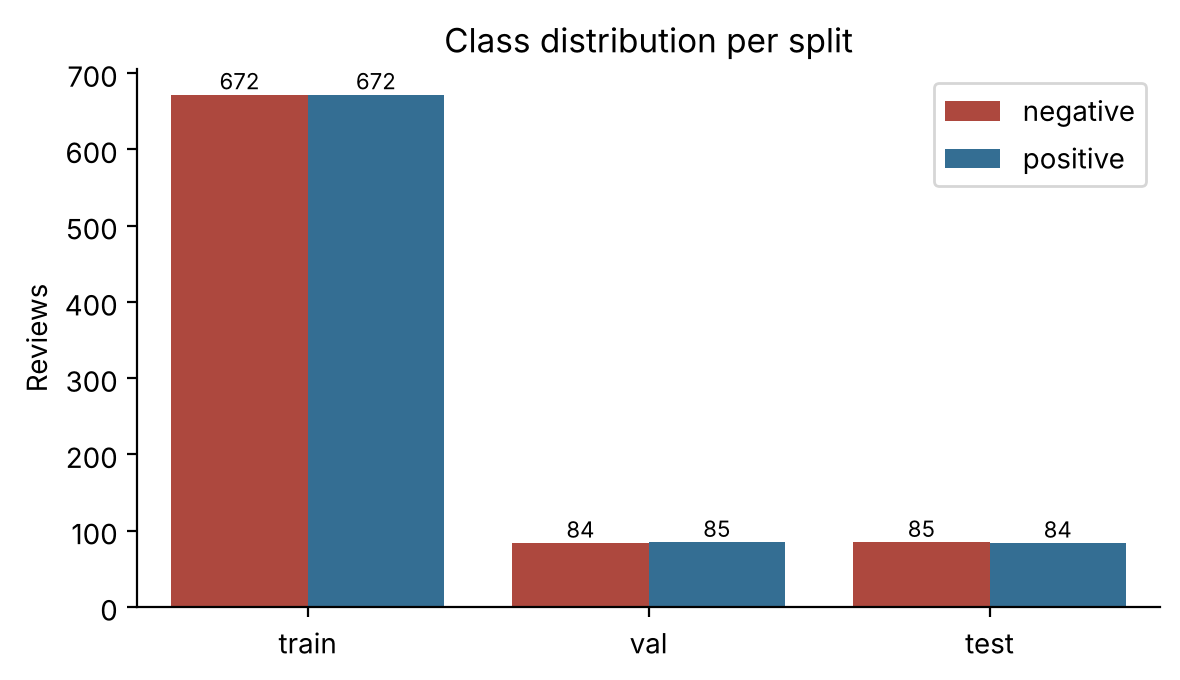

In [3]:
display(result.distribution)
plots.plot_class_distribution(result.distribution);

## 2. Review length
Lengths are right-skewed, so classes are compared with a rank test (Mann-Whitney U). The black line marks the 256-token max length planned for BERTić.

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,672.0,466.262,211.511,21.0,328.75,437.0,546.5,1835.0
positive,672.0,472.004,201.031,60.0,340.75,442.0,556.0,1813.0


Mann-Whitney U: p = 0.340
{128: '99.0%', 256: '89.7%', 512: '33.0%'} <- share of reviews longer than N words


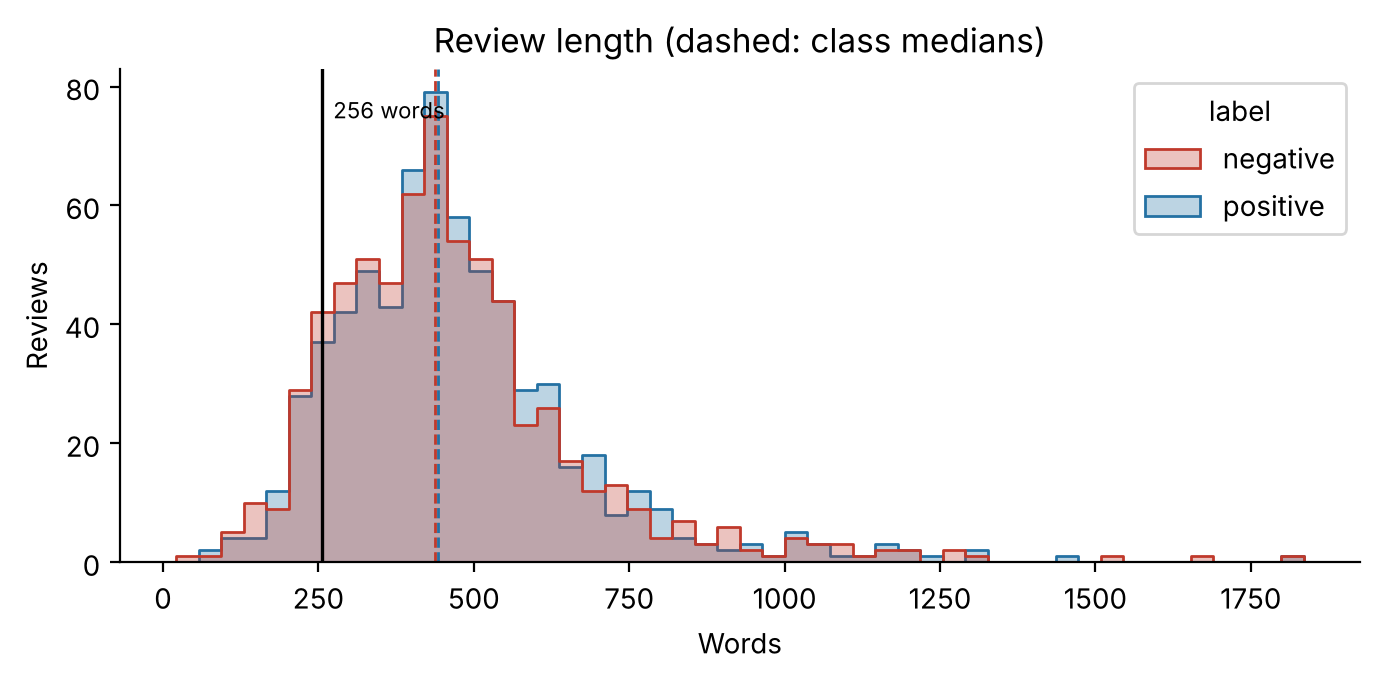

In [4]:
display(result.lengths.summary)
print(f"{result.lengths.test_name}: p = {result.lengths.p_value:.3f}")
print(
    {k: f"{v:.1%}" for k, v in result.truncation.items()}, "<- share of reviews longer than N words"
)
plots.plot_length_distribution(train);

## 3. Vocabulary and morphology

In [5]:
v = result.vocab
print(
    f"tokens={v.n_tokens:,}  types={v.n_types:,}  hapax={v.hapax_share:.1%}  "
    f"val OOV tokens={v.oov_token_rate:.1%}  val OOV types={v.oov_type_rate:.1%}"
)
result.forms

tokens=630,998  types=76,631  hapax=55.4%  val OOV tokens=7.8%  val OOV types=27.4%


{'film': 4308,
 'filma': 2422,
 'filmu': 1247,
 'filmom': 189,
 'filmovi': 221,
 'filmova': 561,
 'filmove': 217,
 'filmovima': 225}

## 4. Most informative words (χ²)
χ² test of word *presence* vs. class. Each word is assigned to the class where it appears in more reviews.

,label,word,chi2,p_value,doc_share_negative,doc_share_positive
5070,negative,nažalost,42.025,9.011e-11,0.180,0.058
4052,negative,loše,31.953,1.579e-08,0.162,0.060
4359,negative,minuta,28.557,9.097e-08,0.251,0.125
4051,negative,loša,25.130,5.358e-07,0.060,0.009
1303,negative,dosadan,21.356,3.815e-06,0.057,0.010
10219,negative,trebalo,18.450,1.744e-05,0.219,0.122
2996,negative,jadno,18.000,2.209e-05,0.027,0.000
4050,negative,loš,17.610,2.712e-05,0.089,0.033
6295,negative,očajno,17.190,3.381e-05,0.030,0.001
5422,negative,ništa,16.780,4.197e-05,0.351,0.231


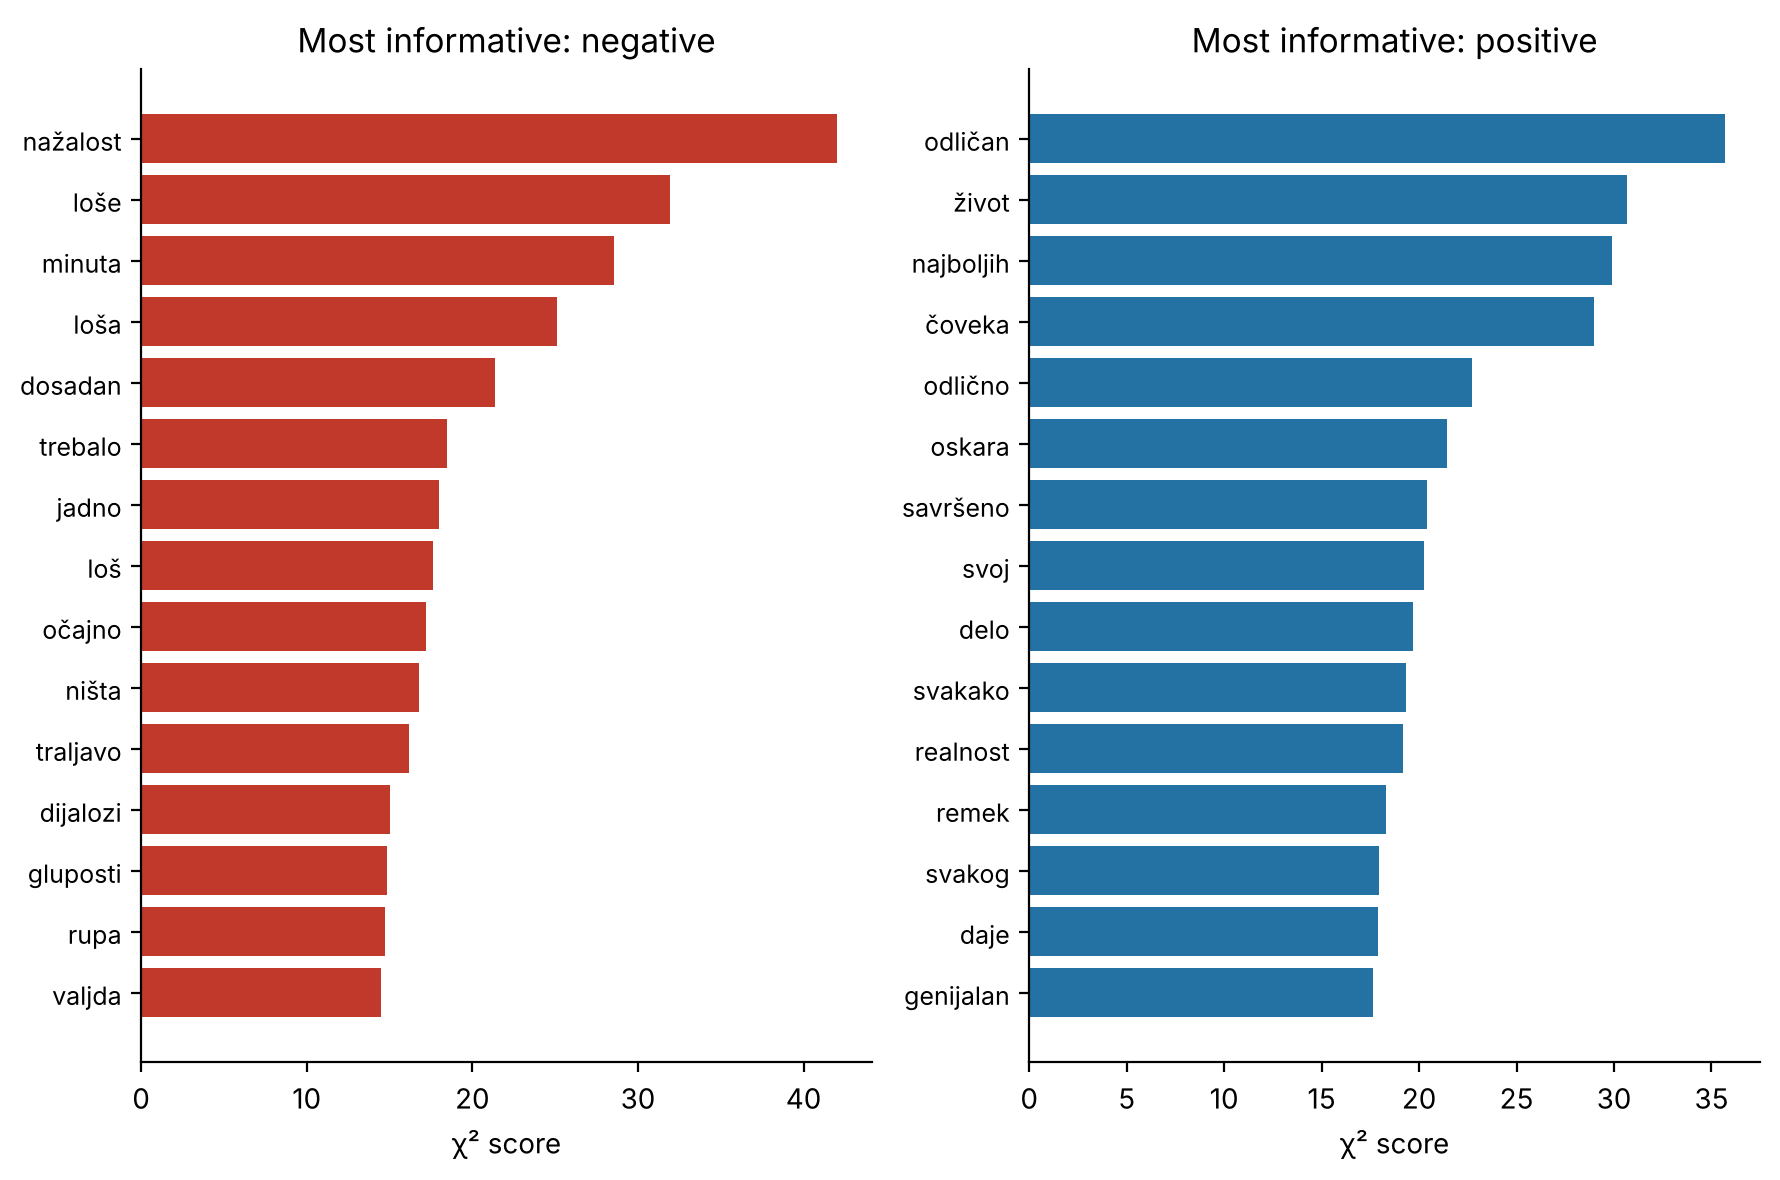

In [6]:
plots.plot_informative_words(result.informative)
result.informative.groupby("label").head(10)

## 5. Most frequent words per class (stopwords removed)
Raw frequency is dominated by topic words common to both classes, which is why χ² is the better lens for sentiment.

In [7]:
pd.DataFrame({lab: [f"{w} ({c})" for w, c in words] for lab, words in result.frequent.items()})

,negative,positive
0,su (2393),su (2214)
1,iz (1114),iz (1063)
2,ako (671),on (736)
3,više (651),više (639)
4,ima (627),ima (582)
5,on (611),ako (527)
6,priča (485),može (523)
7,može (467),iako (502)
8,ovog (449),priča (492)
9,nema (420),ovog (434)


## 6. Lexical cues: negation, punctuation, explicit scores

,per100_negative,docs_negative,per100_positive,docs_positive,ratio
negation (ne/nije/nisam/nisu),1.512,0.984,1.334,0.979,1.133
question mark,0.180,0.400,0.121,0.307,1.485
exclamation mark,0.170,0.314,0.139,0.259,1.222
ellipsis,0.209,0.440,0.185,0.418,1.131
explicit score (e.g. 7/10),0.001,0.004,0.000,0.000,NaN


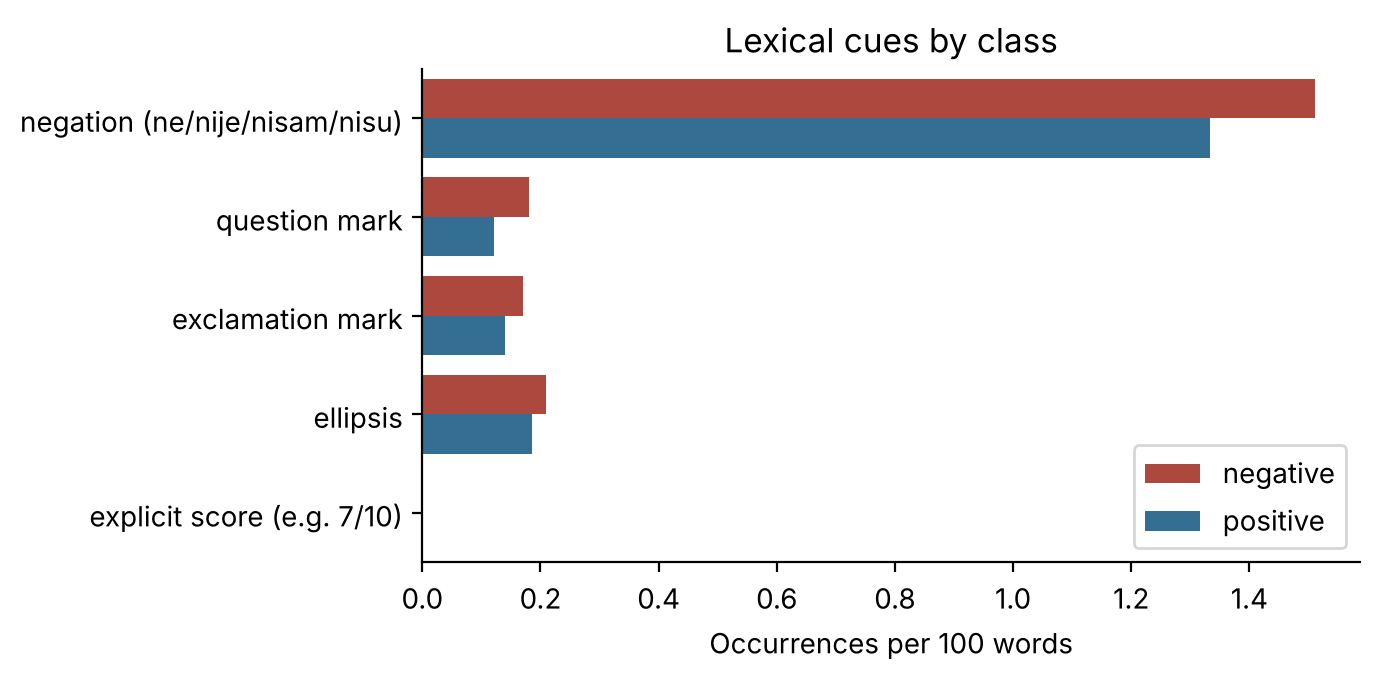

In [8]:
plots.plot_cue_rates(result.cues)
result.cues

## 7. A look at examples
Positive reviews that contain a strong negative cue (*nažalost*, "unfortunately"): an early example of the mixed-sentiment cases expected in error analysis.

In [9]:
mask = train["text"].str.contains(r"\bnažalost\b", case=False) & (train["label"] == "positive")
print(f"{mask.sum()} positive reviews contain 'nažalost'")
for text in train.loc[mask, "text"].head(2):
    i = text.lower().find("nažalost")
    print("...", text[max(0, i - 150) : i + 150], "...\n")

39 positive reviews contain 'nažalost'
...  i na politiku ubeđivanja zemljoposednika da prodaju prava na svoje zemljište, tim više There Will Be Blood ima kapacitet da obuzme, ako ne i osvoji. Nažalost, poslednja trećina filma je s najmanjim fokusom i, dok se nazire jasan završetak, oseća se čudna plitkost. There Will Be Blood je snimljen pr ...

...  ostaje i malo frustriran prizorima koji, iako su među najboljim koje je viđao po hororima (poslednja scena na potoku, recimo), na značenjskom nivou, nažalost, ne objašnjavaju ama baš ništa. Zbog toga... ...

